# FORGE 16B(78)-32 DTS waterfall plots

Run each cell with **Shift + Enter**, top to bottom. Run the setup cell first every time you open this notebook.

- `time_step=10` keeps every 10th time sample to save memory. Use a smaller number for more detail, a larger one if you run out of memory.
- `depth_range=(top, bottom)` in ft trims the plot, e.g. `(0, 11000)` to cut off fiber beyond the well.
- Use **Change from start** to make thermal slugs stand out, then narrow the **Color range** slider.

## Setup

In [1]:
%matplotlib widget
import numpy as np
import h5py
from datetime import datetime, timezone
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display
from JIN_pylib import Data2D_XT


def load_forge_dts(fname, time_step=10, depth_range=(0,11000)):
    """Load a FORGE DTS .h5 file (data/depth/stamps_unix layout) into a Data2D object.
    time_step: keep every Nth time sample (10 = 1/10th of the data, saves memory).
    depth_range: (top, bottom) in ft to keep, or None for everything."""
    with h5py.File(fname, 'r') as h:
        depth = h['depth'][:]
        if depth_range == (0,11000):
            dsl = slice(None)
        else:
            idx = np.where((depth >= depth_range[0]) & (depth <= depth_range[1]))[0]
            dsl = slice(idx[0], idx[-1] + 1)
        t = h['stamps_unix'][::time_step].astype(float)
        data = h['data'][::time_step, dsl]          # (time, depth)
        unit = h['data'].attrs.get('DataUnitLabel', 'F')
    if np.nanmedian(t) > 1e11:                      # milliseconds -> seconds
        t = t / 1000.0
    d = Data2D_XT.Data2D()
    d.data = data.T                                 # Data2D wants (depth, time)
    d.daxis = depth[dsl]
    d.start_time = datetime.fromtimestamp(t[0], tz=timezone.utc).replace(tzinfo=None)
    d.taxis = t - t[0]
    d.attrs['source'] = fname
    d.attrs['unit'] = unit if isinstance(unit, str) else unit.decode()
    return d


def interactive_waterfall(d, title=''):
    """Waterfall plot with a color-range slider, colormap menu, and a
    toggle between absolute temperature and change from the first trace."""
    views = {'Temperature': d.data,
             'Change from start': d.data - d.data[:, [0]]}
    unit = d.attrs.get('unit', 'F')

    fig, ax = plt.subplots(figsize=(11, 6))
    plt.sca(ax)
    d.plot_waterfall(cmap='jet', use_timestamp=True, xtickN=6)
    im = ax.images[0]
    cbar = fig.colorbar(im, ax=ax)
    ax.set_ylabel('Measured depth (ft)')
    ax.set_title(title)

    mode = widgets.ToggleButtons(options=list(views), description='Show:')
    crange = widgets.FloatRangeSlider(description='Color range', step=0.1,
                                      continuous_update=False, readout_format='.1f',
                                      layout=widgets.Layout(width='700px'))
    cmap = widgets.Dropdown(options=['jet', 'turbo', 'viridis', 'inferno', 'RdBu_r', 'coolwarm'],
                            value='jet', description='Colormap')

    def set_mode(change=None):
        arr = views[mode.value]
        lo, hi = float(np.nanmin(arr)), float(np.nanmax(arr))
        p1, p99 = (float(v) for v in np.nanpercentile(arr, [1, 99]))
        crange.max = max(hi, crange.max)
        crange.min = lo
        crange.max = hi
        crange.value = (p1, p99)
        im.set_data(arr)
        im.set_clim(p1, p99)
        cbar.set_label(f'{mode.value} (°{unit})')
        fig.canvas.draw_idle()

    def set_clim(change):
        im.set_clim(*crange.value)
        fig.canvas.draw_idle()

    def set_cmap(change):
        im.set_cmap(cmap.value)
        fig.canvas.draw_idle()

    mode.observe(set_mode, names='value')
    crange.observe(set_clim, names='value')
    cmap.observe(set_cmap, names='value')
    set_mode()
    display(widgets.VBox([mode, crange, cmap]))
    return fig


In [2]:
import pandas as pd

def _times_to_seconds(t_unix, stamps):
    """Return unix time in seconds, handling s/ms/us/ns units, falling back
    to the text timestamps if the numbers don't look like real dates."""
    t = np.asarray(t_unix, dtype=float)
    med = np.nanmedian(np.abs(t)) if np.isfinite(t).any() else 0
    for limit, factor in [(1e17, 1e9), (1e14, 1e6), (1e11, 1e3)]:
        if med > limit:
            t = t / factor
            break
    good = np.isfinite(t) & (t > 946684800) & (t < 4102444800)   # year 2000-2100
    if good.mean() > 0.99:
        return t, 'stamps_unix'
    txt = [s.decode() if isinstance(s, bytes) else str(s) for s in stamps]
    try:
        dt = pd.to_datetime(txt, format='%m/%d/%Y %H:%M:%S.%f')
    except Exception:
        dt = pd.to_datetime(txt, format='mixed')
    return (dt - pd.Timestamp('1970-01-01')).total_seconds().to_numpy(), 'stamps (text)'


def load_forge_dts(fname, time_step=10, depth_range=(0, 11000)):
    """Load a FORGE DTS .h5 file (data/depth/stamps layout) into a Data2D object."""
    with h5py.File(fname, 'r') as h:
        depth = h['depth'][:]
        if depth_range == (0,11000):
            dsl = slice(None)
        else:
            idx = np.where((depth >= depth_range[0]) & (depth <= depth_range[1]))[0]
            dsl = slice(idx[0], idx[-1] + 1)
        t_raw = h['stamps_unix'][::time_step] if 'stamps_unix' in h else np.full(1, np.nan)
        stamps = h['stamps'][::time_step] if 'stamps' in h else None
        data = h['data'][::time_step, dsl]
        unit = h['data'].attrs.get('DataUnitLabel', 'F')
    print('First raw time values:', t_raw[:2], '| first text stamp:', stamps[0] if stamps is not None else None)
    t, used = _times_to_seconds(t_raw, stamps)
    print('Times taken from:', used)
    d = Data2D_XT.Data2D()
    d.data = data.T
    d.daxis = depth[dsl]
    d.start_time = pd.Timestamp(t[0], unit='s').to_pydatetime()
    d.taxis = t - t[0]
    d.attrs['source'] = fname
    d.attrs['unit'] = unit if isinstance(unit, str) else unit.decode()
    return d

## July 2023 circulation test: EVO 1

In [3]:
from datetime import datetime

july_evo1 = load_forge_dts(r'July 2023 Circulation Test/Utah Forge 16B(78)-32 - DTS - mmf 2 - evo 1.h5', time_step=1, depth_range=(0,10200))
july_evo1.print_info()

First raw time values: [1.68944508e+15 1.68944534e+15] | first text stamp: b'07/15/2023 12:18:01.000000'
Times taken from: stamps_unix
Start time: 2023-07-15 18:18:01
taxis: 0.0 - 444138.0 seconds
time interval: min: 256.0, max: 2478.0, median: 257.0
daxis: 2.987945556640625 - 10198.6484375
data dimension: (3059, 1720)
data size: 21 MB
taxis dimension: (1720,)
daxis dimension: (3059,)
history: []


First raw time values: [1.68944508e+15 1.68944534e+15] | first text stamp: b'07/15/2023 12:18:01.000000'
Times taken from: stamps_unix
Start time: 2023-07-15 18:18:01
taxis: 0.0 - 444138.0 seconds
time interval: min: 256.0, max: 2478.0, median: 257.0
daxis: 2.987945556640625 - 10198.6484375
data dimension: (3059, 1720)
data size: 21 MB
taxis dimension: (1720,)
daxis dimension: (3059,)
history: []


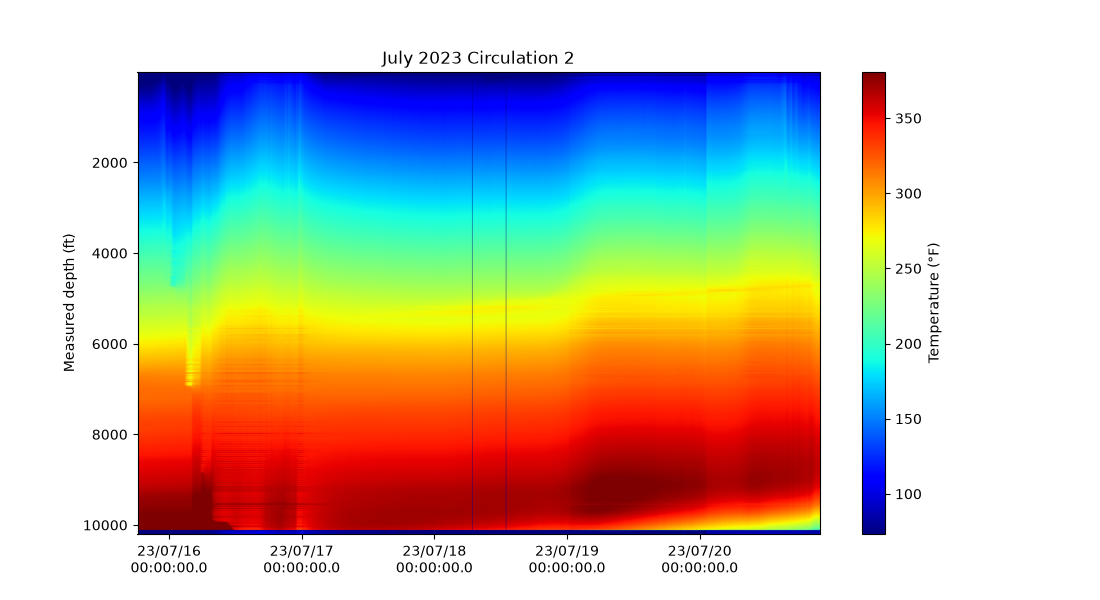

In [4]:
july_evo1 = load_forge_dts(r'July 2023 Circulation Test/Utah Forge 16B(78)-32 - DTS - mmf 2 - evo 1.h5', time_step=1, depth_range=(0,10200))
july_evo1.print_info()
interactive_waterfall(july_evo1, 'July 2023 Circulation 2');

Start time: 2023-07-18 16:04:06
taxis: 0.0 - 107716.0 seconds
time interval: min: 256.0, max: 258.0, median: 257.0
daxis: 2.987945556640625 - 10198.6484375
data dimension: (3059, 420)
data size: 5 MB
taxis dimension: (420,)
daxis dimension: (3059,)
history: []


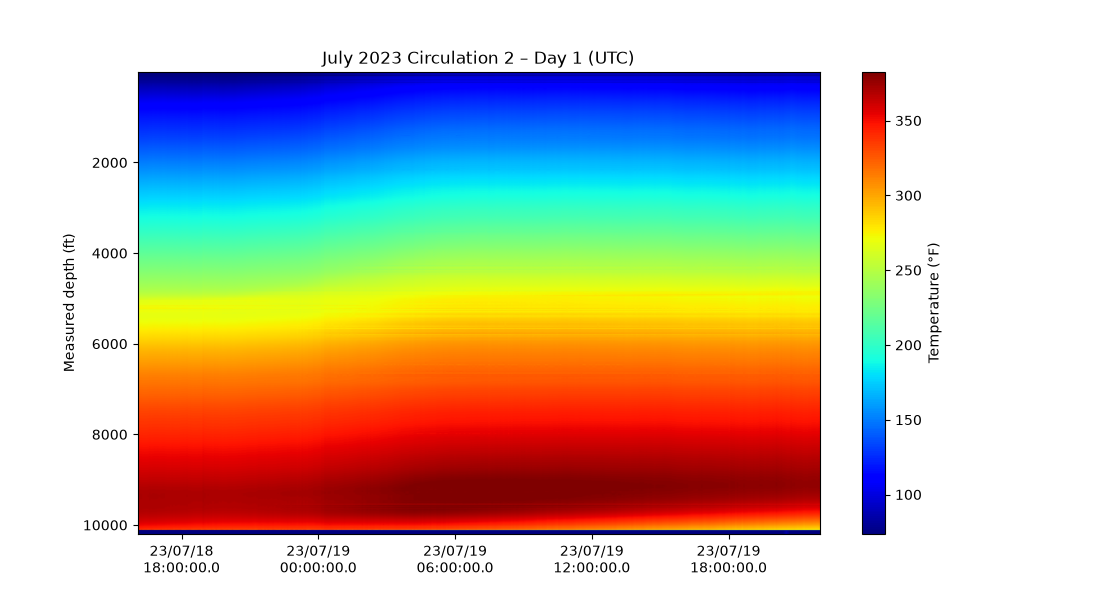

In [5]:
day1 = july_evo1.select_time(datetime(2023,7,18,16,0), datetime(2023,7,19,22,0), makecopy=True)
day1.print_info()
interactive_waterfall(day1, 'July 2023 Circulation 2 – Day 1 (UTC)');

Start time: 2023-07-19 22:03:39
taxis: 0.0 - 71632.0 seconds
time interval: min: 256.0, max: 2478.0, median: 257.0
daxis: 2.987945556640625 - 10198.6484375
data dimension: (3059, 271)
data size: 3 MB
taxis dimension: (271,)
daxis dimension: (3059,)
history: []


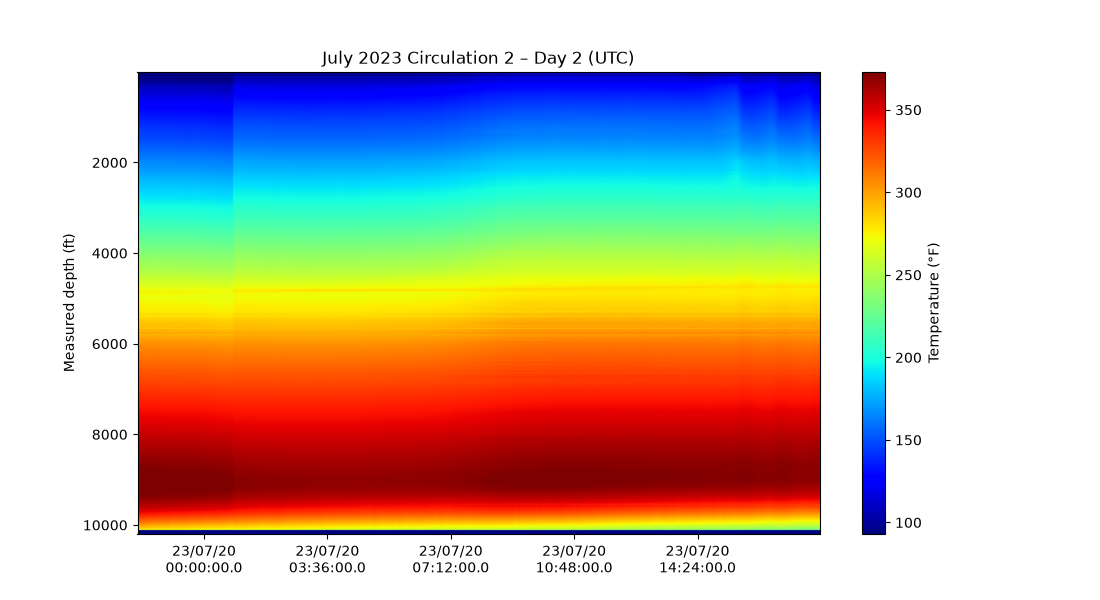

In [6]:
day2 = july_evo1.select_time(datetime(2023,7,19,22,0), datetime(2023,7,20,18,0), makecopy=True)
day2.print_info()
interactive_waterfall(day2, 'July 2023 Circulation 2 – Day 2 (UTC)');

## April 2024 circulation test: EVO 3

Start time: 2024-04-27 18:10:00
taxis: 0.0 - 62370.0 seconds
time interval: min: 30.0, max: 30.0, median: 30.0
daxis: 4201.90234375 - 9747.755859375
data dimension: (1665, 2080)
data size: 13 MB
taxis dimension: (2080,)
daxis dimension: (1665,)
history: []


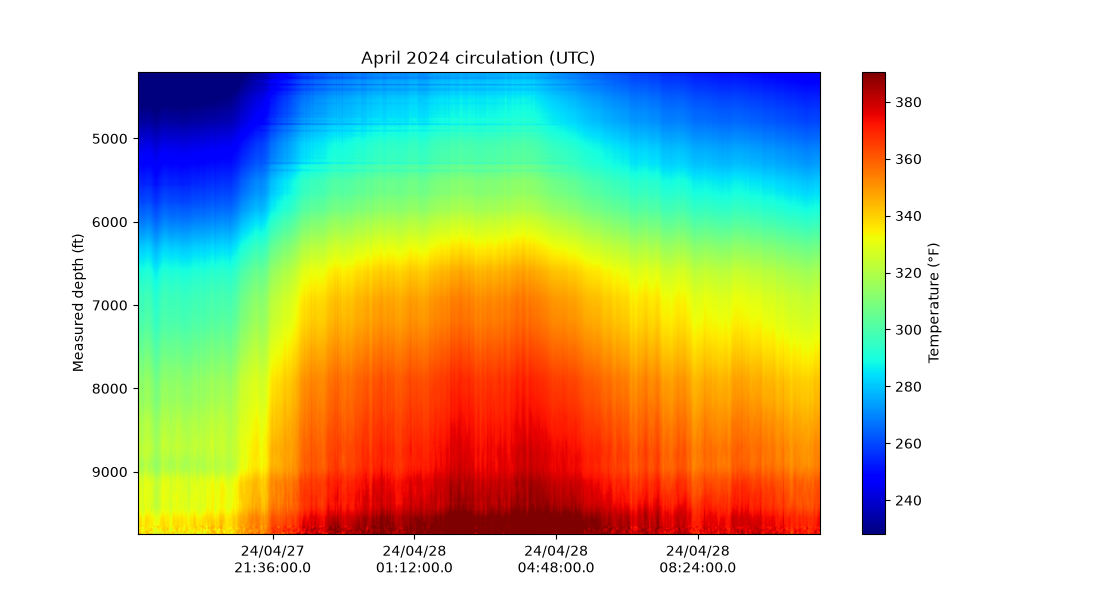

In [7]:
from datetime import datetime

def load_forge_dts_window(fname, start, end, depth_range=None):
    """Load only the times between start and end (UTC datetimes) at full time resolution."""
    with h5py.File(fname, 'r') as h:
        depth = h['depth'][:]
        if depth_range is None:
            dsl = slice(None)
        else:
            idx = np.where((depth >= depth_range[0]) & (depth <= depth_range[1]))[0]
            dsl = slice(idx[0], idx[-1] + 1)
        t, _ = _times_to_seconds(h['stamps_unix'][:], h['stamps'][:] if 'stamps' in h else None)
        s = (start - datetime(1970, 1, 1)).total_seconds()
        e = (end - datetime(1970, 1, 1)).total_seconds()
        rows = np.where((t >= s) & (t < e))[0]
        r0, r1 = rows[0], rows[-1] + 1
        data = h['data'][r0:r1, dsl]
        unit = h['data'].attrs.get('DataUnitLabel', 'F')
    t = t[r0:r1]
    d = Data2D_XT.Data2D()
    d.data = data.T
    d.daxis = depth[dsl]
    d.start_time = pd.Timestamp(t[0], unit='s').to_pydatetime()
    d.taxis = t - t[0]
    d.attrs['source'] = fname
    d.attrs['unit'] = unit if isinstance(unit, str) else unit.decode()
    return d

circ = load_forge_dts_window(
    r'April 2024 Circulation Test/Utah Forge 16B(78)-32 - DTS calibrated - mmf 2 - evo 3.h5',
    datetime(2024, 4, 27, 18, 10), datetime(2024, 4, 28, 11, 30),
    depth_range=(4200, 9750))
circ.print_info()
interactive_waterfall(circ, 'April 2024 circulation (UTC)');

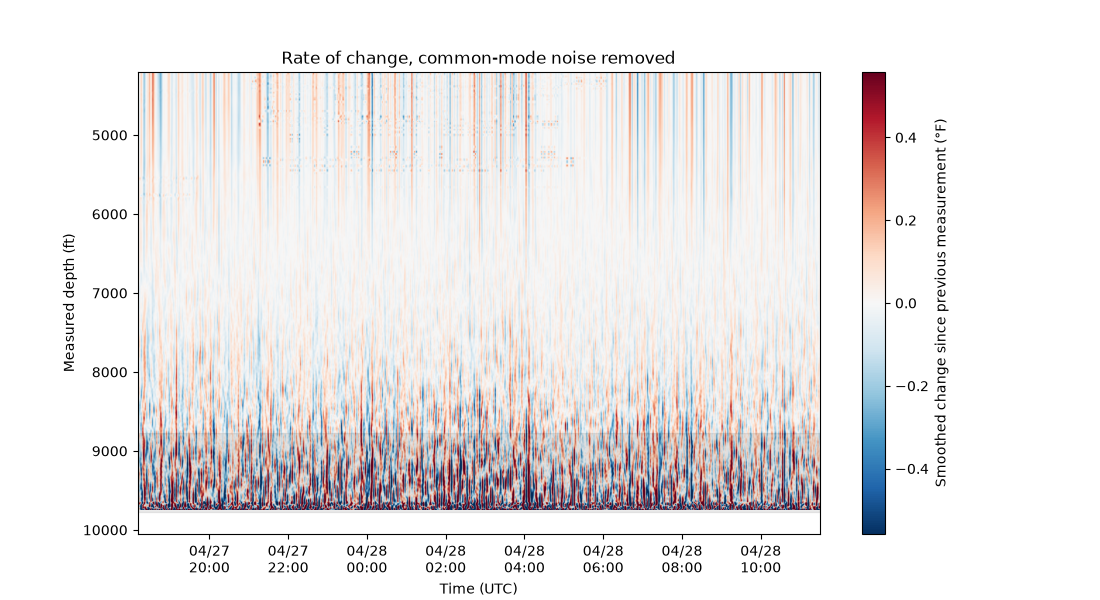

In [8]:
from datetime import timedelta
from scipy.ndimage import uniform_filter
import matplotlib.dates as mdates

DEPTH_SMOOTH = 9    # points (~30 ft)
TIME_SMOOTH = 5     # measurements (~11 min)

sm = uniform_filter(circ.data.astype(float), size=(DEPTH_SMOOTH, TIME_SMOOTH), mode='nearest')
rate = np.diff(sm, axis=1)
rate = rate - np.nanmedian(rate, axis=0, keepdims=True)   # remove whole-trace (common-mode) shifts
lim = np.nanpercentile(np.abs(rate), 98)
times = [mdates.date2num(circ.start_time + timedelta(seconds=float(s))) for s in circ.taxis[1:]]

fig, ax = plt.subplots(figsize=(11, 6))
im = ax.imshow(rate, aspect='auto', cmap='RdBu_r', vmin=-lim, vmax=lim,
               extent=[times[0], times[-1], circ.daxis[-1], circ.daxis[0]])
ax.xaxis_date()
ax.xaxis.set_major_formatter(mdates.DateFormatter('%m/%d\n%H:%M'))
ax.axhspan(8774, 9773, color='k', alpha=0.08)
fig.colorbar(im, label='Smoothed change since previous measurement (°F)')
ax.set_ylabel('Measured depth (ft)')
ax.set_xlabel('Time (UTC)')
ax.set_title('Rate of change, common-mode noise removed');

## August 2024 extended circulation test: EVO 4 

First raw time values: [1.72349067e+15 1.72349080e+15] | first text stamp: b'08/12/2024 19:24:32.000000'
Times taken from: stamps_unix
Start time: 2024-08-12 19:24:32
taxis: 0.0 - 326875.0 seconds
time interval: min: 128.0, max: 2588.0, median: 129.0
daxis: 2.497833251953125 - 10094.36328125
data dimension: (1515, 2269)
data size: 13 MB
taxis dimension: (2269,)
daxis dimension: (1515,)
history: []


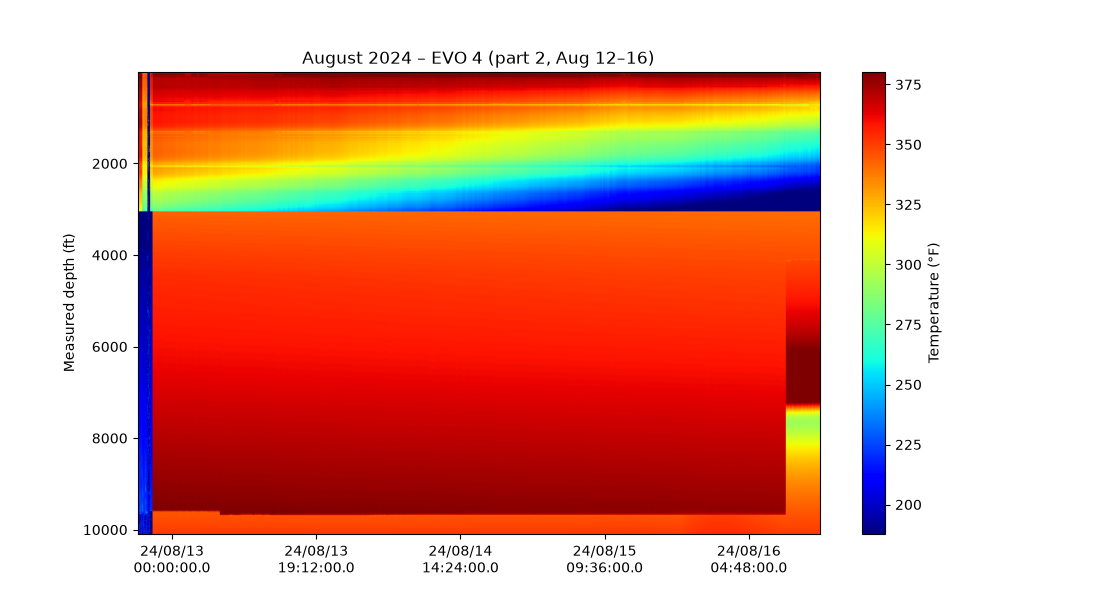

In [9]:
aug2024 = load_forge_dts(r'August 2024 Extended Circulation Test/Utah Forge 16B(78)-32 - DTS - mmf 2 - evo 4 - part 2.h5',
                         time_step=1, depth_range=(0, 10100))
aug2024.print_info()
interactive_waterfall(aug2024, 'August 2024 – EVO 4 (part 2, Aug 12–16)');

First raw time values: [1.72279521e+15 1.72279556e+15] | first text stamp: b'08/04/2024 18:13:32.000000'
Times taken from: stamps_unix


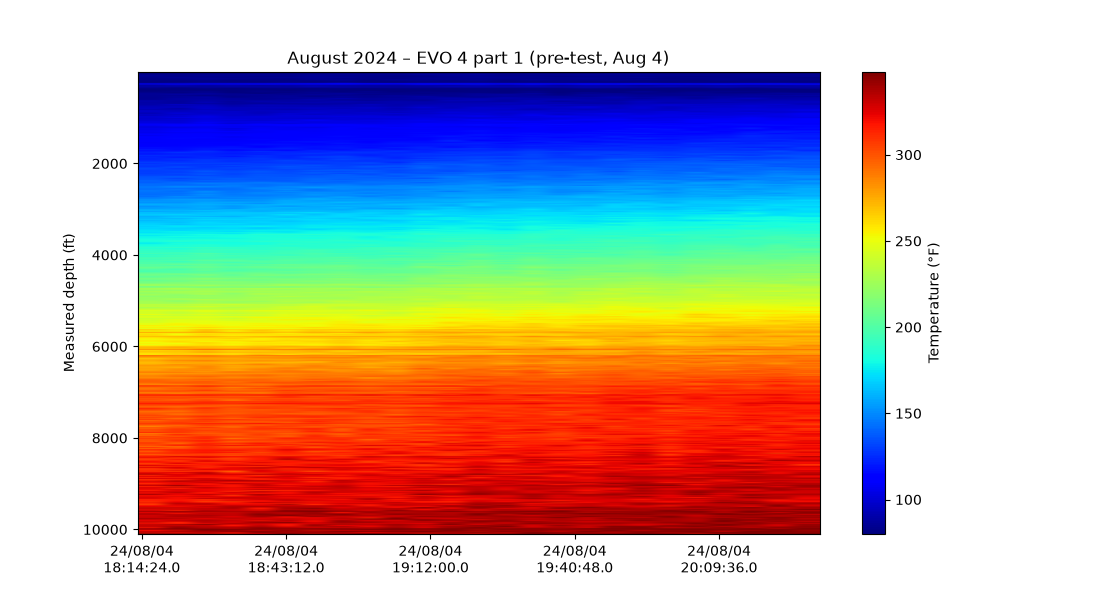

In [10]:
aug_base = load_forge_dts(r'August 2024 Extended Circulation Test/Utah Forge 16B(78)-32 - DTS - mmf 2 - evo 4 - part 1.h5',
                          time_step=1, depth_range=(0, 10100))
interactive_waterfall(aug_base, 'August 2024 – EVO 4 part 1 (pre-test, Aug 4)');

## August 2025 circulation and huff-and-puff tests: EVO 5

First raw time values: [1.75542574e+15 1.75542607e+15] | first text stamp: b'08/17/2025 10:15:43.000000'
Times taken from: stamps_unix
Start time: 2025-08-17 10:15:43
taxis: 0.0 - 1127815.0 seconds
time interval: min: 331.0, max: 43912.0, median: 331.0
daxis: -0.5333251953125 - 10994.56640625
data dimension: (3282, 3254)
data size: 42 MB
taxis dimension: (3254,)
daxis dimension: (3282,)
history: []


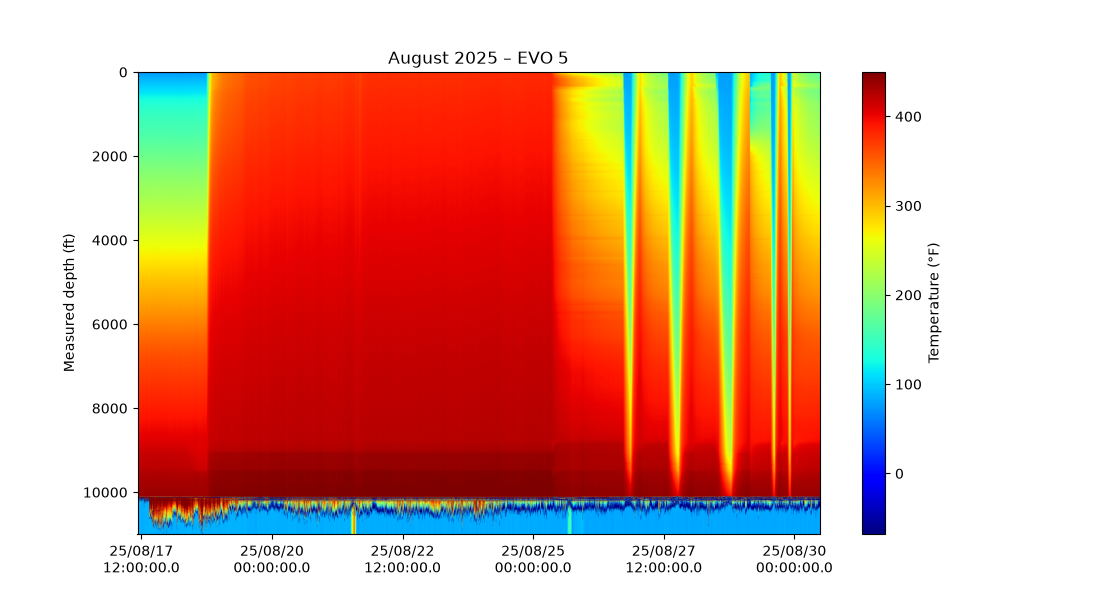

In [11]:
aug2025 = load_forge_dts(r'August 2025 Circulation and Huff-and-puff Tests/Utah Forge 16B(78)-32 - DTS calibrated - evo 5.h5', time_step=10, depth_range=(0,11000))
aug2025.print_info()
interactive_waterfall(aug2025, 'August 2025 – EVO 5');

Start time: 2025-08-21 15:00:12
taxis: 0.0 - 8983.0 seconds
time interval: min: 32.0, max: 34.0, median: 33.0
daxis: 5002.73291015625 - 10079.7001953125
data dimension: (1516, 272)
data size: 1 MB
taxis dimension: (272,)
daxis dimension: (1516,)
history: []


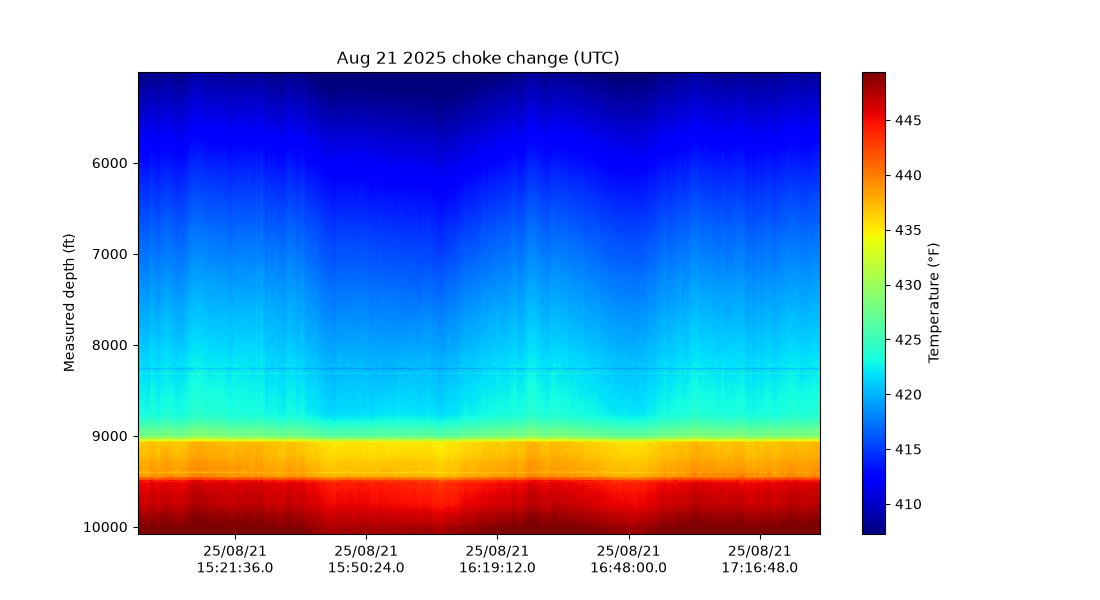

In [12]:
slug = load_forge_dts_window(
    r'August 2025 Circulation and Huff-and-puff Tests/Utah Forge 16B(78)-32 - DTS calibrated - evo 5.h5',
    datetime(2025, 8, 21, 15, 0), datetime(2025, 8, 21, 17, 30),
    depth_range=(5000, 10080))
slug.print_info()
interactive_waterfall(slug, 'Aug 21 2025 choke change (UTC)');

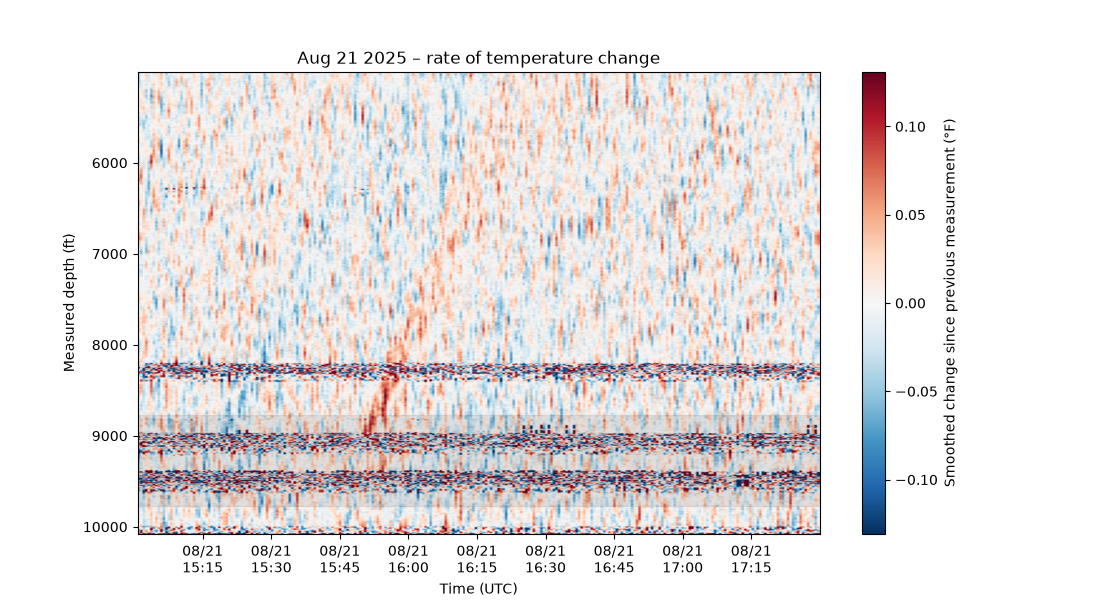

In [13]:
from datetime import timedelta
from scipy.ndimage import uniform_filter
import matplotlib.dates as mdates

DEPTH_SMOOTH = 5    # points
TIME_SMOOTH = 3     # measurements (~1.75 min)

sm = uniform_filter(slug.data.astype(float), size=(DEPTH_SMOOTH, TIME_SMOOTH), mode='nearest')
rate = np.diff(sm, axis=1)
rate = rate - np.nanmedian(rate, axis=0, keepdims=True)   # remove whole-trace noise
lim = np.nanpercentile(np.abs(rate), 98)
times = [mdates.date2num(slug.start_time + timedelta(seconds=float(s))) for s in slug.taxis[1:]]

fig, ax = plt.subplots(figsize=(11, 6))
im = ax.imshow(rate, aspect='auto', cmap='RdBu_r', vmin=-lim, vmax=lim,
               extent=[times[0], times[-1], slug.daxis[-1], slug.daxis[0]])
ax.xaxis_date()
ax.xaxis.set_major_formatter(mdates.DateFormatter('%m/%d\n%H:%M'))
ax.axhspan(8774, 9773, color='k', alpha=0.08)   # 16B stage zone
fig.colorbar(im, label='Smoothed change since previous measurement (°F)')
ax.set_ylabel('Measured depth (ft)')
ax.set_xlabel('Time (UTC)')
ax.set_title('Aug 21 2025 – rate of temperature change');

In [14]:
# ---- Settings: a box around the streak ----
T_START, T_END = datetime(2025, 8, 21, 15, 48), datetime(2025, 8, 21, 16, 6)   # UTC
D_TOP, D_BOTTOM = 7400, 8950                                                   # ft
SKIP = [(8180, 8400)]        # noisy fixed-depth bands to ignore
SIGN = +1                    # +1 red (warming) streak, -1 blue (cooling) streak
MAX_OFF_S = 90               # drop picks more than this many seconds off the fitted line
# Optional hand-drawn exclusion boxes: (start time, end time, top depth, bottom depth)
EXCLUDE = [
    # (datetime(2025, 8, 21, 15, 48), datetime(2025, 8, 21, 15, 55), 7400, 8100),
]
# -------------------------------------------

tnum = np.array(times)
t0, t1 = mdates.date2num(T_START), mdates.date2num(T_END)
cols = np.where((tnum >= t0) & (tnum <= t1))[0]
pick_d, pick_t = [], []
for i, dep in enumerate(slug.daxis):
    if dep < D_TOP or dep > D_BOTTOM or any(a <= dep <= b for a, b in SKIP):
        continue
    k = cols[np.argmax(SIGN * rate[i, cols])]
    pt = tnum[k]
    if any(mdates.date2num(a) <= pt <= mdates.date2num(b) and top <= dep <= bot
           for a, b, top, bot in EXCLUDE):
        continue
    pick_d.append(dep)
    pick_t.append(pt)
pick_d, pick_t = np.array(pick_d), np.array(pick_t)
secs = (pick_t - pick_t.min()) * 86400

# Fit time vs depth (picks are uncertain in time), dropping outliers until stable
keep = np.ones(len(secs), bool)
for _ in range(10):
    fit = np.polyfit(pick_d[keep], secs[keep], 1)
    new_keep = np.abs(secs - np.polyval(fit, pick_d)) <= MAX_OFF_S
    if (new_keep == keep).all():
        break
    keep = new_keep
fit, cov = np.polyfit(pick_d[keep], secs[keep], 1, cov=True)
speed = -1 / fit[0]                                   # ft/s (negative slope: rises with time)
err = abs(speed) * np.sqrt(cov[0, 0]) / abs(fit[0])
print(f'Front speed: {speed:.2f} ± {err:.2f} ft/s  '
      f'({keep.sum()} points kept, {(~keep).sum()} dropped)')

ax.plot(pick_t[~keep], pick_d[~keep], 'x', color='gray', ms=4, label='dropped')
ax.plot(pick_t[keep], pick_d[keep], 'k.', ms=3, label='kept')
dd = np.array([pick_d[keep].min(), pick_d[keep].max()])
ax.plot(pick_t.min() + np.polyval(fit, dd) / 86400, dd, 'k-', lw=1.5,
        label=f'fit: {speed:.2f} ft/s')
ax.legend(loc='upper right')
fig.canvas.draw_idle()

Front speed: 2.35 ± 0.03 ft/s  (224 points kept, 173 dropped)


In [15]:
SEGMENTS = [(7400, 8100, 'upper'), (8400, 8900, 'lower')]   # (top, bottom, name) in ft
SAMPLE_S = 35

for top, bot, name in SEGMENTS:
    m = keep & (pick_d >= top) & (pick_d <= bot)
    if m.sum() < 10:
        print(f'{name}: too few points'); continue
    f, c = np.polyfit(pick_d[m], secs[m], 1, cov=True)
    v = -1 / f[0]
    e = abs(v) * np.sqrt(c[0, 0]) / abs(f[0])
    n_samples = (bot - top) / abs(v) / SAMPLE_S
    flag = '' if n_samples >= 5 else '  <-- too short to trust'
    print(f'{name} ({top}-{bot} ft): {v:.2f} ± {e:.2f} ft/s, '
          f'crossed in ~{n_samples:.0f} measurements{flag}')

upper (7400-8100 ft): 2.48 ± 0.10 ft/s, crossed in ~8 measurements
lower (8400-8900 ft): 2.17 ± 0.12 ft/s, crossed in ~7 measurements
